# Gravitational Wave Signal Detection

This project explores the detection of gravitational waves in noisy strain data using **matched filtering** and a bank of simulated gravitational-wave templates.

Gravitational waves are ripples in spacetime produced by the acceleration of massive objects, such as merging black holes. They are detected by interferometers such as the **Laser Interferometer Gravitational-Wave Observatory (LIGO)**, which measure extremely small changes in the relative lengths of their arms. The resulting strain data is dominated by detector noise, making signal-processing techniques essential for identifying potential gravitational-wave signals.

The main aim of this project is to develop a Python-based search algorithm capable of identifying gravitational-wave signals without prior knowledge of the properties of the source. The analysis uses **matched filtering**, comparing detector strain against theoretical waveform templates and calculating the signal-to-noise ratio (SNR). A template bank containing waveforms with different binary black hole masses is then used to determine which template provides the strongest match to the data.

The notebook covers:

* Generating binary black hole waveform templates using **PyCBC**
* Preparing detector strain data for frequency-domain analysis
* Estimating the **power spectral density (PSD)** of detector noise
* Computing matched-filter SNR and SNR time series
* Constructing and searching a bank of waveform templates
* Searching longer stretches of LIGO strain data for candidate signals
* Comparing detections between the Hanford and Livingston detectors

The final search is applied to real LIGO strain data, demonstrating how matched filtering can be used to identify candidate gravitational-wave signals within noisy data.


## Housekeeping 

We first complete some necessary housekeeping code for the project, importing the relevant packages and defining the necessary constants.

In [2]:
# Import the necessary libraries and packages required for this project
import pycbc.waveform
import pycbc
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
import math
import scipy
import lal as _lal
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

In [3]:
# Define the necessary constants to be used throughout the project
sampling_frequency = 1024
duration = 1
dt = 1./sampling_frequency # separation of samples in seconds

## Generating a Test Waveform

First, a test gravitational-wave waveform is generated using `PyCBC`. The waveform represents a binary black hole merger with component masses of $36M_{\odot}$ and $30M_{\odot}$ solar masses, with the merger occurring at $t=0$.

A 1-second window is then extracted around the merger, with 0.75 seconds of the waveform before the merger and 0.25 seconds after it. This provides a test signal that can be compared with noisy strain data.

The waveform is generated using the `IMRPhenomPv2` approximant, with a lower frequency of 30 Hz and a source distance of 500 Mpc. The function returns the two gravitational-wave polarisations, $h_+$ and $h_\times$.

In [4]:
# Generate an initial test gravitational-wave waveform
hplus, hcross = pycbc.waveform.get_td_waveform(mass1=36,mass2=30,distance=500,approximant='IMRPhenomPv2',f_lower=30, delta_t=dt)

# Define some initial variables
psd_mag = 1.0e-46#(2e-23)**2               # set a fixed psd magnitude
Nt = sampling_frequency*duration   # define length of time series
df = 1./duration                   # frequency separation

# Extract a 1-second window centred around the merger
merger_index = np.argmin(np.abs(hplus.sample_times)) # Find the sample index of the merger
times_window = hplus.sample_times[merger_index - int(0.75*Nt) : merger_index + int(0.25*Nt)] # Select the time window around the merger
filter = hplus[int(merger_index - 0.75*Nt) : int(merger_index + 0.25*Nt)] # Extract 1s of the waveform surrounding the merger

The generated waveform is compared with a set of test strain data containing a simulated signal and noise. This provides a simple test case for the matched-filtering functions developed below.

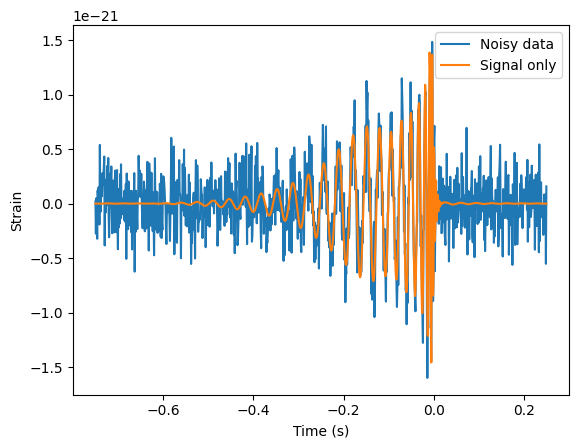

In [5]:
# Load in some test data
with open('./data/DET/DET_white_data_ts.txt', "r") as f:
    times, data = np.loadtxt(f).T

# Plot the test data against the test signal generated
fig, ax = plt.subplots()
ax.plot(times_window, data, label = "Noisy data")
ax.plot(times_window, filter, label = "Signal only")
ax.set_ylabel("Strain")
ax.set_xlabel("Time (s)")
ax.legend()

## Computing the Matched-Filter SNR

Now that we have a candidate GW waveform and a set of noisy detector data, we can begin the process of matched filtering. The matched filter SNR compares the candidate waveform with the detector data in the frequency domain, while weighting the comparison according to the detector's noise power spectral density. This gives a measure of how closely the waveform matches the data while accounting for the frequency-dependent noise of the detector. A higher SNR indicates a stronger match between the template and the data.

The noise-weighted inner product between the detector data \(s\) and a template waveform \(h\) is

$$
(s | h) = 4\,\mathrm{Re}\int_0^\infty
\frac{\tilde{s}(f)\tilde{h}^*(f)}{S_n(f)}\,df.
$$

The matched-filter SNR is then

$$
\rho = \frac{(s|h)}{\sqrt{(h|h)}}.
$$

Here, $\tilde{s}(f)$ and $\tilde{h}(f)$ are the Fourier transforms of the detector data and template waveform respectively, $\tilde{h}^*(f)$ is the complex conjugate of the template, and $S_n(f)$ is the detector's noise power spectral density (more on this later).

In practice, the data is sampled at discrete time intervals \(dt\), giving \(N\) samples and a total duration

$$
T = N\,dt.
$$

The frequency-domain integral is therefore evaluated as a discrete sum over frequency bins. With the Fourier transform convention used here, the inner product becomes

$$
(s | h) =
\frac{4}{T}\,
\mathrm{Re}
\sum_k
\frac{\tilde{s}_k\tilde{h}_k^*}{S_n(f_k)}.
$$

The same definition is used for the template's self-inner product,

$$
(h | h) =
\frac{4}{T}
\sum_k
\frac{|\tilde{h}_k|^2}{S_n(f_k)},
$$

which provides the normalisation in the SNR.


In [6]:
def compute_snr(template, data, psd, dt):
    # Determine the number of samples and total duration of the data
    N = len(template)
    data_duration = N * dt

    # Compute FFTs of the data and template
    detector_fft = np.fft.rfft(data)*dt
    template_fft = np.fft.rfft(template)*dt

    # Compute the noise-weighted inner product between the data and template
    s_inner_h = np.real(4/data_duration*np.sum(np.conj(template_fft)*detector_fft/psd))

    # Compute the noise-weighted inner product of the template with itself
    h_norm = (4 / data_duration) * np.sum(np.abs(template_fft)**2 / psd)

    # Compute the matched-filter SNR
    snr = s_inner_h/np.sqrt(h_norm)

    return snr

## Computing the Matched-Filter SNR Timeseries

The previous calculation gives a single SNR value for a given waveform and dataset. However, this does not tell us when the waveform best matches the data.

We can instead calculate the SNR as a function of time:

$$
\rho(t) = \frac{4}{\sqrt{(h|h)}} \mathrm{Re}\int_0^\infty
\frac{\tilde{s}(f)\tilde{h}^*(f)}{S_n(f)}
e^{2\pi i f t}\,df
$$

This is equivalent to taking the template and sliding it through the detector data, calculating the matched-filter SNR at each position. The result is an SNR timeseries showing how strongly the template matches the data at each point in time.

If there is a gravitational-wave signal buried in the data, we expect a peak in the SNR timeseries when the template best matches the signal. The peak therefore gives both the strength of the best match and the time at which it occurs.

### The Calculation Process
First, the data and template are transformed into the frequency domain:

$$ \tilde{s}(f) = \mathcal{F}\{s(t)\} , \qquad \tilde{h}(f) = \mathcal{F}\{h(t)\}.$$

The frequency-domain matched filter is then

$$\rho_f(f) = \frac{4}{dt} \frac{\tilde{h}^*(f)\tilde{s}(f)}{S_n(f)}.$$

Here, $\rho_f$ is an array containing the contribution from each frequency bin. It is not yet the matched-filter inner product itself, because the frequency contributions have not yet been summed together.

Taking the inverse Fourier transform performs this summation while also applying the phase factors corresponding to different time shifts:

$$\rho_t(t) = \frac{1}{2} \mathcal{F}^{-1}\{\rho_f(f)\}. $$

The factor of $1/dt$ in $\rho_f$ may initially seem different from the $1/T$ factor used in the definition of the inner product. However, the inverse Fourier transform contains a factor of $1/N$, where $N$ is the number of samples. Therefore, the inverse transform produces the same $4/T$ normalisation as the standard inner product, but now for every time shift of the template.

The inverse Fourier transform reconstructs a real time-domain signal from the positive-frequency components. For a real signal, the corresponding negative-frequency components contain the same information, so the positive and negative frequency contributions are represented together when reconstructing the real signal. The resulting `irfft` therefore gives twice the positive-frequency contribution, requiring the result to be divided by $2$:

$$\rho_t(t) = \frac{1}{2} \mathcal{F}^{-1}\{\rho_f(f)\}. $$

The template is then normalised using same quantity as the $(h|h)$ calculated in the previous method; the calculation of this in the code is simply a more compact form of the inner produce with itself.

Finally, dividing the matched-filter timeseries by the square root of the template norm gives the SNR timeseries:

$$\rho(t) = \frac{\rho_t(t)}{\sqrt{(h|h)}}. $$

The result is therefore the same matched-filter SNR calculation as before, but evaluated at **every possible time shift of the template** rather than at just one alignment.

In [7]:
def alt_snr(template, data, psd, dt):
    # Determine the number of samples and total duration of the data
    N = len(data)
    data_duration = N * dt

    # Compute FFTs, zero-padding the template to the length of the data
    template_fft = np.fft.rfft(template, n=N) * dt
    detector_fft = np.fft.rfft(data) * dt

    # Compute the frequency-domain matched filter
    rho_f = (4/ dt) * np.conj(template_fft) * detector_fft / psd

    # Transform back to the time domain to obtain the SNR numerator
    rho_t = np.fft.irfft(rho_f, n=N) / 2

    # Compute the template norm for SNR normalisation
    h_norm = (4 / data_duration) * np.sum(np.abs(template_fft)**2 / psd)


    # Normalise to obtain the SNR timeseries
    snr = rho_t / np.sqrt(h_norm)

    return np.real(snr)

## Detecting a Known Gravitational-Wave Event

The next step is to apply the matched-filtering method to gravitational-wave detector data containing a known signal. Two data files are provided:

* **`DET2_white_noise_ts.txt`** – contains a section of detector data containing noise only. This is used to estimate the detector's noise power spectral density (PSD) without the gravitational-wave signal affecting the estimate.
* **`DET2_white_data_ts.txt`** – contains detector data with an injected gravitational-wave signal from a binary black-hole merger with component masses \(m_1 = 36\,M_\odot\) and \(m_2 = 30\,M_\odot\).

### Estimating the Noise Power Spectral Density (PSD)

The PSD describes how the noise power is distributed across different frequencies. It is required when calculating the matched-filter SNR because the contribution from each frequency should be weighted according to the noise present at that frequency.

The PSD is estimated from the noise-only data using the **Welch method**. This divides the data into segments, calculates a power spectrum for each segment, and averages the results to produce a more robust estimate of the underlying noise spectrum.

Before calculating the PSD, a **Tukey window** is applied to the data. A finite section of a time series can introduce discontinuities when Fourier transformed, which can lead to spectral leakage. Multiplying the data by a window function reduces these edge effects by smoothly bringing the data towards zero at the boundaries. A Tukey window with $\alpha=0.3$ is used here.

The same window is also applied to the signal-containing data before performing the matched filtering.

### Searching for the Signal

The gravitational-wave template generated in the previous section has the same known binary parameters as the injected signal, $m_1=36\,M_\odot$ and $m_2=30\,M_\odot$. We can therefore use this template to search the detector data for the expected signal.

The `alt_snr` function developed in the previous section is used to calculate the **matched-filter SNR timeseries**. This efficiently evaluates the SNR for different time alignments between the template and the detector data, allowing us to determine when the template provides the best match.

If the gravitational-wave signal is successfully detected, we expect the SNR timeseries to show a clear peak when the template is aligned with the signal. The time corresponding to the maximum of the SNR timeseries is therefore taken as the estimated merger time.

The resulting SNR timeseries, detector strain data, Tukey window and estimated PSD are plotted below. The recovered merger time and SNR are also printed for comparison with the known injected signal.


In [8]:
# Import the noise-only data for estimating the detector PSD
with open('./data/DET/DET2_white_noise_ts.txt', "r") as f: 
    times1, data1 = np.loadtxt(f).T

# Import the detector data containing the injected gravitational-wave signal
with open('./data/DET/DET2_white_data_ts.txt', "r") as f:
    times2, data2 = np.loadtxt(f).T

# Estimate the noise PSD using a Tukey-windowed Welch periodogram
nperseg = 1024
psd_wind = scipy.signal.windows.tukey(nperseg, alpha=0.3)
psd_welch = scipy.signal.welch(data1, fs=1/dt, nperseg=nperseg, window=psd_wind)
psd_avg = np.average(psd_welch[1]) # Use the mean PSD as the noise estimate for the matched filter

# Calculate the matched-filter SNR timeseries using the template from the previous section
rho1 = alt_snr(filter, data2 * psd_wind, psd_avg, dt)
rho1 = np.roll(rho1, int(0.75 * len(rho1))) # Shift the SNR timeseries to align it with the corresponding data times

# Find the time corresponding to the maximum SNR
merger_index = np.argmax(rho1)
merger_time = times_window[merger_index]

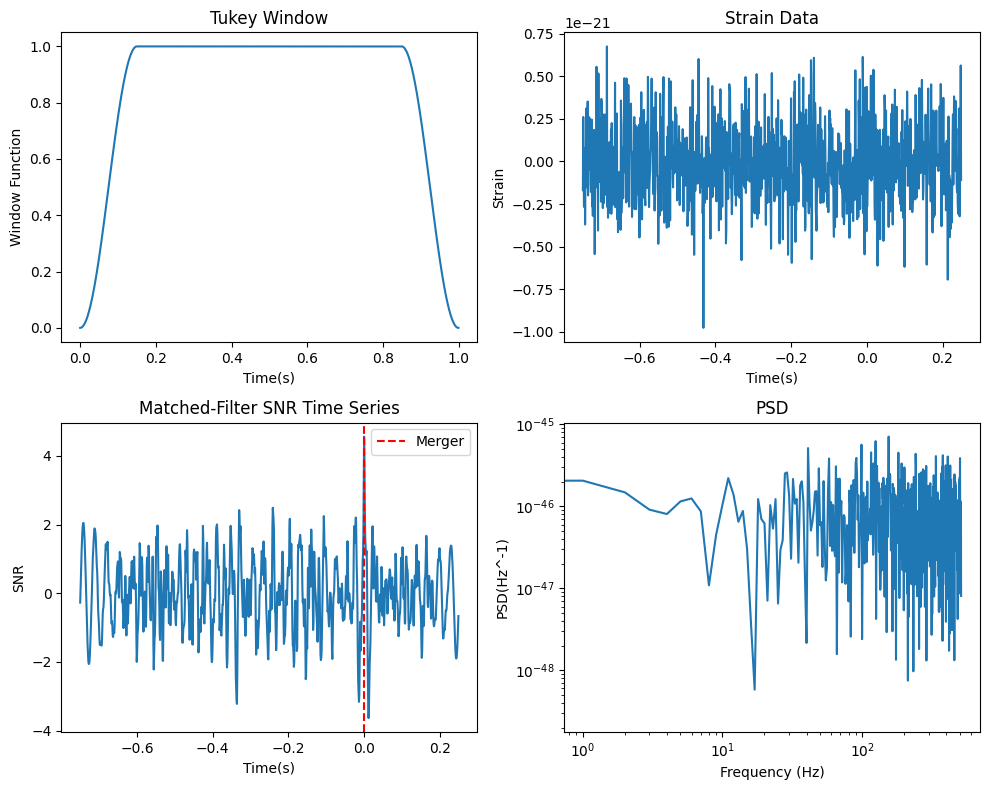

Merger time: 0.0s
SNR: 4.560460667506427


In [9]:
plt.figure(figsize=(10,8))
plt.subplot(2,2,1)
plt.plot(times1, psd_wind)
plt.ylabel("Window Function")
plt.xlabel("Time(s)")
plt.title("Tukey Window")

plt.subplot(2,2,2)
plt.plot(times_window, data2)
plt.ylabel("Strain")
plt.xlabel("Time(s)")
plt.title("Strain Data")

plt.subplot(2,2,3)
plt.plot(times_window, rho1)
plt.axvline(merger_time,color="r", label = "Merger", linestyle = "dashed")
plt.ylabel("SNR")
plt.xlabel("Time(s)")
plt.title("Matched-Filter SNR Time Series")
plt.legend()

plt.subplot(2,2,4)
plt.loglog(psd_welch[0], psd_welch[1])
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD(Hz^-1)")
plt.title("PSD")
plt.tight_layout()
plt.show()

print(f"Merger time: {merger_time}s")
print(f"SNR: {max(rho1)}")

A merger time of 0 seconds is obtained, with an SNR value of 4.56 - a fairly satisfactory value given how noisy the strain data appears to be. The merger time of 0 seconds is due to the fact that the default convention for GW templates in PyCBC is for the merger to occur at t = 0.
From looking at the strain graph, it can be seen that a spike occurs (at ∼ −0.2s) which does not appear to coincide with the peak of the SNR graph - this does not necessarily mean that the signal has been incorrectly detected. A spike in a strain graph will only produce a peak in the SNR graph if the data matches the expected waveform template that is being used for matched filtering. Therefore, this spike is likely just a random noise spike.

## Creating a Template Bank

### Choosing the Template Bank
Up until this point, the matched filter has assumed that the masses of the binary are already known. This is not realistic for a general gravitational-wave search, where the source parameters are initially unknown. To overcome this, I created a **template bank** containing waveforms generated using different combinations of component masses. Each template can then be compared with the detector data, with the template producing the highest SNR giving the best estimate of the signal's masses.

For this search, I chose a mass range of **20-40 solar masses** for both components. I then used `np.linspace` to divide this range into 8 equally spaced values:

$$m = [20,\ 22.86,\ 25.71,\ 28.57,\ 31.43,\ 34.29,\ 37.14,\ 40]\ M_\odot.$$

The two nested loops in `event_search()` (see below) combine every value of $m_1$ with every value of $m_2$. This produces $8\times8=64$ different mass combinations, and therefore 64 templates.

The number of templates is a compromise between **accuracy and computational cost**. A finer mass grid would provide more closely spaced templates and could give a more accurate estimate of the binary masses, but would also require more waveforms to be generated and more SNR calculations to be performed. I therefore chose 8 mass values in each dimension, giving 64 templates, as a reasonable balance between the resolution of the search and the time required to run it.

In [10]:
min_mass = 20
max_mass = 40
num_masses = 8
mass_vector = np.linspace(min_mass, max_mass, num_masses)

## Building and searching through the bank
The `event_search()` function performs the search over the entire template bank. For each combination of `m1` and `m2`, a gravitational-wave template is generated using the same waveform model and sampling parameters as the known-mass search.

The waveform is then centred on the merger and a 1-second section is extracted, containing **0.75 seconds before merger and 0.25 seconds after merger**. This gives a consistent template length for every mass combination while retaining the part of the waveform most relevant to the merger.

The template is passed to the `alt_snr()` function along with the detector data and averaged PSD. This produces an SNR time series showing how strongly that particular template matches the data at each point in time. The maximum value of this time series is then recorded, along with the corresponding time.

This process is repeated for all 64 templates. The resulting list contains the component masses, maximum SNR, merger time and SNR time series for every mass combination. Finally, `max()` is used to identify the template with the **highest SNR**, giving the mass combination that provides the best match to the data.

The template-bank search therefore allows the signal parameters to be estimated without assuming the masses in advance.


In [11]:
def event_search(mass_vector, data, times, psd_avg):
    sampling_frequency = 1024
    dt = 1./sampling_frequency # separation of samples in seconds
    Nt = len(data)   # define length of time series
    results = []
    for m1 in mass_vector:
        for m2 in mass_vector:
            # generate waveform
            hplus, hcross = pycbc.waveform.get_td_waveform(mass1=m1, mass2=m2, distance=500, approximant='IMRPhenomPv2', 
                                                       f_lower=30, delta_t=dt)
        
            # find merger and extract 1s window
            merger_index = np.argmin(np.abs(hplus.sample_times))
            win_left  = int(0.75 * sampling_frequency)
            win_right = int(0.25 * sampling_frequency)

            start = merger_index - win_left
            end   = merger_index + win_right

            template = hplus[start:end]
            times_window = hplus.sample_times[merger_index - int(0.75*Nt) : merger_index + int(0.25*Nt)]

            # compute SNR time series
            rho = alt_snr(template, data, psd_avg, dt)

            # record max SNR and time
            idx = np.argmax(rho)
            snr = rho[idx]
            results.append({"m1": m1, "m2": m2, "snr": snr, "time": times[idx], "snrt": rho})
    return results

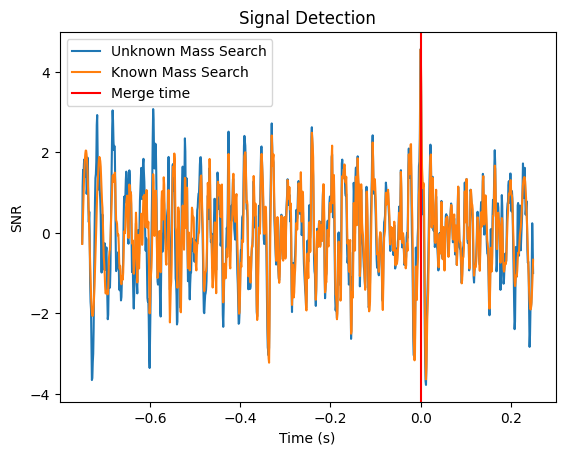

In [12]:
best = max(event_search(mass_vector, data2, times2, psd_avg), key=lambda x: x["snr"])
snrt = np.roll(best["snrt"], int(0.75*len(best["snrt"])))

plt.figure()
plt.plot(times_window, snrt, label = "Unknown Mass Search")
plt.plot(times_window, rho1, label = "Known Mass Search")
plt.axvline(best["time"], color="r", label = "Merge time")

plt.title("Signal Detection")
plt.xlabel("Time (s)")
plt.ylabel("SNR")
plt.legend()
plt.savefig("Unknown_mass.png")
plt.show()

As can be seen in the output, the two SNR time series show a reasonable agreement with each other, with slight amplitude differences at the inspiral and ringdown stages - these are likely due to the slightly different masses used in the templates used. The search produced
a mass one value of $31.42M_{\odot}$ and a mass two value of $34.29M_{\odot}$. These values are in reasonable agreement with the expected values of $30M_{\odot}$ and $36M_{\odot}$ respectively, and looking at the values within the ”linspaced” mass vector - these are the closest available values to the expected values. This is a good indication of the accuracy of the search algorithm.

## Hunting for Unknown Signals
The template-bank search can now be extended to a longer dataset in order to search for **multiple gravitational-wave signals**. Instead of analysing one short section of data, we load a longer strain dataset containing data from the Hanford (H1) and Livingston (L1) LIGO detectors.

For this first search, we use the Hanford strain data, `H1`. The data is divided into smaller sections before being passed to the template-bank search. This allows the search to be repeated across the full dataset rather than assuming that there is only one signal present.

To search for multiple signals, we loop over the full dataset and divide it into fixed-length chunks. Each chunk is passed separately to `event_search()`, which performs the template-bank search described above and returns the template with the highest SNR.

We use a **1-second chunk length** for this search. This does significantly increase computaitonal demand, however, the payoff is a much more thorough search for signal candidates. For each chunk, only the template producing the highest SNR is retained. These results are stored in `bests`, allowing the strongest candidate from each section of the dataset to be compared afterwards.

This approach has an important limitation: because only the **strongest candidate in each chunk** is retained, a second signal occurring within the same chunk may not be identified. The choice of chunk size therefore affects the sensitivity of the search as well as its computational cost.


In [13]:
import math
with open('./data/DET/timeseries_data_multisignal.txt', "r") as f:
    t, H1, L1 = np.loadtxt(f).T

In [14]:
chunk_size = int(2 / dt)  # 1 second = 1024 samples

bests = []

for ind1 in range(0, len(H1), chunk_size):
    ind2 = ind1 + chunk_size

    # Ignore the final chunk if it is shorter than 1 second
    if ind2 > len(H1):
        break

    data_chunk = H1[ind1:ind2]
    time_chunk = t[ind1:ind2]

    best = max(event_search(mass_vector, data_chunk, time_chunk, psd_avg), key=lambda x: x["snr"])
    bests.append(best)

### Identifying Likely Signals
After searching the full dataset, we use the SNR of each detected candidate to distinguish stronger signal candidates from weaker detections. The strongest SNR found across the dataset was used as a reference value.

Candidates with an SNR greater than **70% of the maximum SNR** were classified as having a higher chance of being genuine gravitational-wave signals. Candidates between **60% and 70% of the maximum SNR** were retained separately as lower-confidence candidates.

This relative thresholding provides a simple way of reducing the number of weaker detections that need to be considered, while still retaining candidates that may contain a genuine signal. The higher-confidence detections are shown using solid vertical lines, while the lower-confidence candidates are shown using dashed lines.

The resulting plot therefore shows where the search algorithm identified potential gravitational-wave signals throughout the longer dataset, together with the SNR time series produced by the template-bank search.

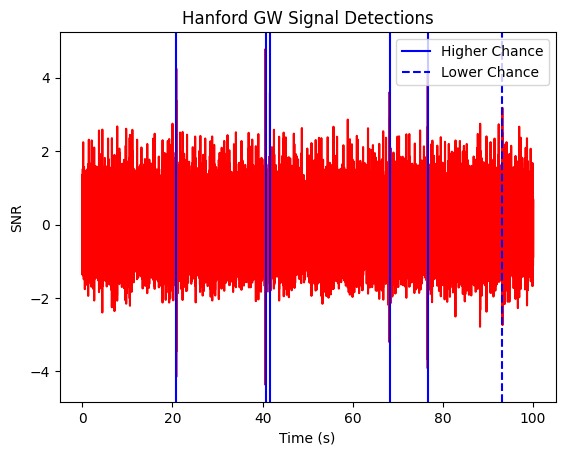

In [26]:
defsig = []
maybesig = []
times_all = np.array([r["time"] for r in bests])
snrts_all = [r["snrt"] for r in bests]
snrs_all = [r["snr"] for r in bests]
m1s_all = [r["m1"] for r in bests]
m2s_all = [r["m2"] for r in bests]

for x in range(len(snrts_all)):
    plt.plot(t[x*len(snrts_all[x]):(x+1)*len(snrts_all[x])], snrts_all[x], color = "red")

for x in range(len(bests)):
    if snrs_all[x]>0.7*max(snrs_all):
        defsig.append({"m1": m1s_all[x], "m2": m2s_all[x], "snr": snrs_all[x], "time": times_all[x], "snrt": snrts_all[x]})
    elif snrs_all[x]>0.6*max(snrs_all) and snrs_all[x]<0.7*max(snrs_all):
        maybesig.append({"m1": m1s_all[x], "m2": m2s_all[x], "snr": snrs_all[x], "time": times_all[x], "snrt": snrts_all[x]})

deft = np.array([r["time"] for r in defsig])
maybet = np.array([r["time"] for r in maybesig])

for x in deft:
    plt.axvline(x, color = "b", label = "Higher Chance")

for x in maybet:
    plt.axvline(x, color = "b", linestyle = "dashed", label = "Lower Chance")

plt.title("Hanford GW Signal Detections")
plt.xlabel("Time (s)")
plt.ylabel("SNR")
plt.legend()
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.show()

As can be seen from the output, the signals are plotted on top of the SNR time series obtained for each 1-second chunk passed into the search function. There were 6 ”higher chance” signals obtained, and 2 ”lower chance” signals obtained from this search. Looking at the SNR time series, all obvious peaks appear to have signals associated with them - it appears that the most prominent signals have been detected from this dataset. 

The next section takes a closer look at the detection times and mass values obtained from this search.

## Part 4: Incorporating a Second Detector

Having ran the search on the data from the Hanford LIGO detector, we now run it on the same stretch of data, but this time taken on the Livingston LIGO detector, in order to see how the results vary.

We apply the exact same method as in the previous section, passing in the data in in 1-second chunks, and finding the signals that were within 60 and 70% of the strongest signal.

The plot shows the signals obtained from both the Livingston and Hanford detectors.

In [16]:
bests1 = []

for ind1 in range(0, len(L1), chunk_size):
    ind2 = ind1 + chunk_size

    # Ignore the final chunk if it is shorter than 1 second
    if ind2 > len(L1):
        break

    data_chunk = L1[ind1:ind2]
    time_chunk = t[ind1:ind2]

    best = max(event_search(mass_vector, data_chunk, time_chunk, psd_avg), key=lambda x: x["snr"])
    bests1.append(best)

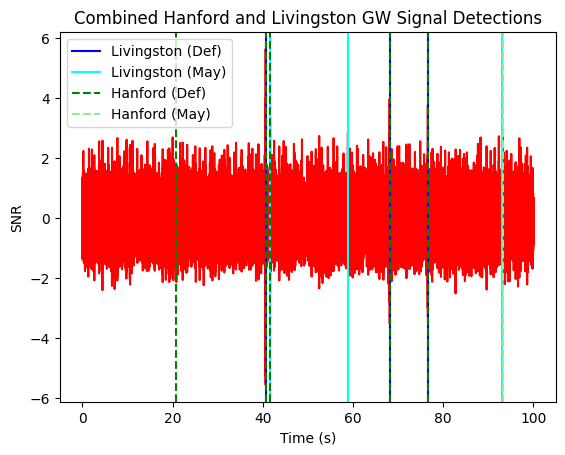

In [36]:
defsig1 = []
maybesig1 = []
times_all1 = np.array([r["time"] for r in bests1])
snrts_all1 = [r["snrt"] for r in bests1]
snrs_all1 = [r["snr"] for r in bests1]
m1s_all1 = [r["m1"] for r in bests1]
m2s_all1 = [r["m2"] for r in bests1]

for x in range(len(snrts_all1)):
    plt.plot(t[x*len(snrts_all1[x]):(x+1)*len(snrts_all1[x])], snrts_all1[x], color = "red")

for x in range(len(bests1)):
    if snrs_all1[x]>0.6*max(snrs_all1):
        defsig1.append({"m1": m1s_all1[x], "m2": m2s_all1[x], "snr": snrs_all1[x], "time": times_all1[x], "snrt": snrts_all1[x]})
    elif snrs_all1[x]>0.5*max(snrs_all1) and snrs_all1[x]<0.6*max(snrs_all1):
        maybesig1.append({"m1": m1s_all1[x], "m2": m2s_all1[x], "snr": snrs_all1[x], "time": times_all1[x], "snrt": snrts_all1[x]})

deft1 = np.array([r["time"] for r in defsig1])
maybet1 = np.array([r["time"] for r in maybesig1])

for x in deft1:
    plt.axvline(x, color = "b", label = "Livingston (Def)")

for x in maybet1:
    plt.axvline(x, color = "cyan", label = "Livingston (May)")

for x in deft:
    plt.axvline(x, color = "g", linestyle = "dashed", label = "Hanford (Def)")

for x in maybet:
    plt.axvline(x, color = "lightgreen", linestyle = "dashed", label = "Hanford (May)")

plt.title("Combined Hanford and Livingston GW Signal Detections")
plt.xlabel("Time (s)")
plt.ylabel("SNR")
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.show()

To keep the comparisons simpler, the plot shows both the higher and lower chance signals (same thresholds as before
apply). It can be seen that most of the signals detected agree with each other, with only a few signals not lining up. We will first take a look at the signals that agree with each other - these are shown below.

### Signals that Agree

Because the signals have came from searches on different datasets, these signals may not be *exactly* equal, and so we print out the results and manually identify the matches and mismatches.

In [39]:
lagg = [deft1[0], deft[1], deft[2], maybesig1[0], maybesig1[2]]
hagg = [deft[1], deft[2], deft[3], deft[4], maybesig]
print("Livingston Agree")
print(lagg)
print("Hanford Agree")
print(hagg)

Livingston Agree
[40.6591796875, 40.66357421875, 41.640625, {'m1': 22.857142857142858, 'm2': 40.0, 'snr': 3.372079518211175, 'time': 41.63916015625, 'snrt': array([-0.20902995,  0.22422857,  0.4850317 , ..., -0.91867774,
       -0.98985697, -0.75525184])}, {'m1': 31.42857142857143, 'm2': 40.0, 'snr': 2.9528310649364022, 'time': 93.18359375, 'snrt': array([ 0.10668693, -0.12449167, -0.25230226, ..., -0.12918053,
        0.14463724,  0.25719449])}]
Hanford Agree
[40.66357421875, 41.640625, 68.16748046875, 76.62451171875, [{'m1': 31.42857142857143, 'm2': 40.0, 'snr': 3.182308043685023, 'time': 93.18505859375, 'snrt': array([ 0.10977787, -0.12128636, -0.24906283, ..., -0.1268572 ,
        0.14727934,  0.26009538])}]]


| Signal Number | $T_H$ (s) | $T_L$ (s) | $M_{1H}$ ($M_{\odot}$) | $M_{1L}$ ($M_{\odot}$) | $M_{2H}$ ($M_{\odot}$) | $M_{2L}$ ($M_{\odot}$) |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 40.66 | 40.66 | 34.29 | 37.14 | 40 | 40 |
| 2 | 41.64 | 41.64 | 25.71 | 22.86 | 40 | 40 |
| 3 | 68.17 | 68.15 | 34.29 | 34.29 | 40 | 34.29 |
| 4 | 76.62 | 76.63 | 40 | 40 | 40 | 40 |
| 5 | 93.19 | 93.18 | 31.43 | 31.43 | 40 | 40 |

The table shows that the signal times from the matched signals show excellent agreement with each other - this is a great indication of the accuracy of the search. Having results from two separate searches on two separate datasets agree with each other is really valuable.

However, there is slightly less agreement between the mass values. This is likely due to the limitations that come with the mass vector used - having only 8 values between 20 and 40 solar does reduce the accuracy with which the mass values can be matched. As previously mentioned, using a larger mass vector then uses a lot more computing power, and makes the code longer to run - this is a sacrifice that I have made in order to be able to split up the data and achieve more accurate signal times.

Another important point to note is that a lot of the M2 values seem to be at the maximum value of 40 solar masses - this suggests that perhaps the mass range should be extended, however, this would mean either adding more templates (and hence computing time), or increasing
the differences between the available mass values (hence decreasing the accuracy). Given the accuracy of the signal times obtained, these results are satisfactory.

We now look at the signals that do not agree.

### Signals That Don't Agree

The first plot shows the Hanford GW signals that were not detected during the Livingston search, plotted on top of the SNR time series obtained from the Livingston search. The second plot shows the Livingston GW signals that were not detected during the Hanford search, plotted on top
of the SNR time series obtained from the Hanford search.

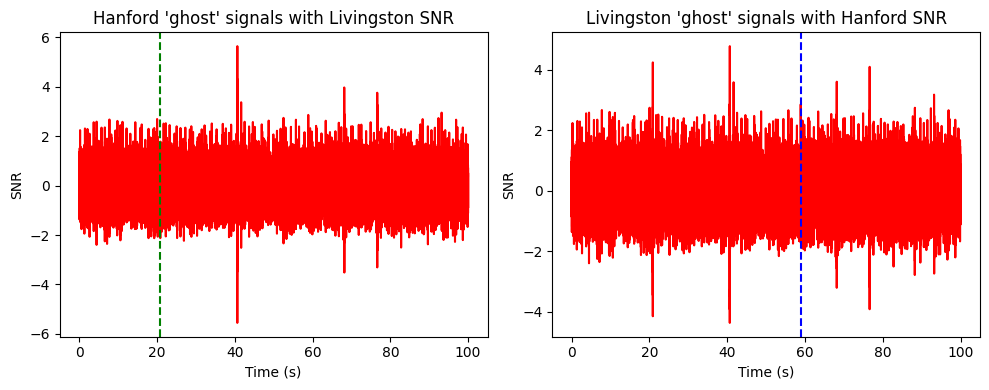

In [41]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
for x in range(len(snrts_all1)):
    plt.plot(t[x*len(snrts_all1[x]):(x+1)*len(snrts_all1[x])], snrts_all1[x], color = "red")

plt.axvline(deft[0], color = "g", linestyle = "dashed")
# plt.axvline(maybet[1], color = "g", linestyle = "dashed")

plt.xlabel("Time (s)")
plt.ylabel("SNR")
plt.title("Hanford 'ghost' signals with Livingston SNR")

plt.subplot(1,2,2)
for x in range(len(snrts_all)):
    plt.plot(t[x*len(snrts_all[x]):(x+1)*len(snrts_all[x])], snrts_all[x], color = "red")

plt.axvline(maybet1[1], color = "b", linestyle = "dashed")

plt.xlabel("Time (s)")
plt.ylabel("SNR")
plt.title("Livingston 'ghost' signals with Hanford SNR")

plt.tight_layout()

The dashed lines allow us to see that there is no SNR spike for either of these signals. Considering that most of the signals detected line up, these differences likely are due to the differences in the detectors themselves. Each detector has a different orientation relative to the source in the sky, meaning the same wave can produce a difference in the measured strain. Additionally, the noise environments of the detectors
can affect the measured SNR and the clarity of the detected waveform - hence resulting in differences in signals detected.

## Conclusions
Overall, this project has successfully achieved it’s aims of detecting gravitational wave signals from a set of string data. This process involved using matched filtering to compute the SNR and SNR time series of a given set of data. This SNR time series can then be used to
identify peaks, and hence find when gravitational wave signals occur.

In order to be able to detect signals without prior knowledge of the masses involved, a template bank was created, which had a grid of 64 mass values between 20 and 40 solar masses. The given dataset could then be passed into a function which performed the matched filtering using each template in the template bank, and returning the signal with the best match.

The search was then run on a longer set of strain data, taken from the Hanford LIGO detector, by passing in 1-second chunks and returning a signal from each 1-second chunk. The returned signals were then looped over, and the highest-SNR signals were returned. The data from a second LIGO detector (Livingston) was then incorporated, and the similarity of the signals was analysed.

Overall, the signals detected showed excellent agreement, with only a few signals in disagreement. These signals in disagreement are most likely due to differences in noise environments and in detector response. The signals that matched both searches showed excellent agreement in detector times, but not as much with the mass values. This is due to the limited amount of mass values used in the template bank. If I could change one thing about this project, and had more computing power available, I would certainly make the template
bank more extensive.